## Load and analyze dataset

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# column names
columns = [
    'age', 'workclass', 'fnlwgt', 'education',
    'education-num', 'marital-status', 'occupation',
    'relationship', 'race', 'sex', 'capital-gain',
    'capital-loss', 'hours-per-week', 'native-country',
    'income'
]

# load dataset
df = pd.read_csv(
    '../data/adult.data',
    header=None,
    names=columns,
    skipinitialspace=True
)

print("Dataset shape:", df.shape)

Dataset shape: (32561, 15)


In [7]:
print(df.head())
print(df.describe())
print(df.info())

# check missing and duplicates
# print(df.isnull().sum()) # no missing values korsatdi lekin ? bunaqala kop ekan
# print(df.duplicated().sum()) # 24 duplicates

   age         workclass  fnlwgt  education  education-num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country income  
0          2174             0              40  United-States  <=50K  
1             0             0             

In [8]:
# analyze individual feature answers
for column in df.columns:
    print(f"\n{column}:")
    print(df[column].value_counts().head(10))


age:
age
36    898
31    888
34    886
23    877
35    876
33    875
28    867
30    861
37    858
25    841
Name: count, dtype: int64

workclass:
workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
?                    1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

fnlwgt:
fnlwgt
123011    13
164190    13
203488    13
148995    12
121124    12
126675    12
113364    12
190290    11
123983    11
120277    11
Name: count, dtype: int64

education:
education
HS-grad         10501
Some-college     7291
Bachelors        5355
Masters          1723
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
Name: count, dtype: int64

education-num:
education-num
9     10501
10     7291
13     5355
14     1723
11     1382
7      1175
12     1067
6       933
4       646
15  

## Data cleaning

In [27]:
# create a copy
df_clean = df.copy()

# replace ? with NaN
df_clean.replace('?', np.nan, inplace=True)

# remove duplicates
df_clean.drop_duplicates(inplace=True)
print(df.duplicated().sum()) # check duplicates after

# i decided to drop education, because education-num is already encoded version of it
df_clean.drop(columns=['education'], inplace=True)

# check datases after cleaning
print(df_clean.head())
print(df_clean.shape)

24
   age         workclass  fnlwgt  education-num      marital-status  \
0   39         State-gov   77516             13       Never-married   
1   50  Self-emp-not-inc   83311             13  Married-civ-spouse   
2   38           Private  215646              9            Divorced   
3   53           Private  234721              7  Married-civ-spouse   
4   28           Private  338409             13  Married-civ-spouse   

          occupation   relationship   race     sex  capital-gain  \
0       Adm-clerical  Not-in-family  White    Male          2174   
1    Exec-managerial        Husband  White    Male             0   
2  Handlers-cleaners  Not-in-family  White    Male             0   
3  Handlers-cleaners        Husband  Black    Male             0   
4     Prof-specialty           Wife  Black  Female             0   

   capital-loss  hours-per-week native-country income  
0             0              40  United-States  <=50K  
1             0              13  United-States  <

## Analyze target

In [28]:
print(df_clean['income'].value_counts()) # so model should predict if person earns more than 50k or less

# income percentages
print(df_clean['income'].value_counts(normalize=True) * 100) # distribuition in percentages

income
<=50K    24698
>50K      7839
Name: count, dtype: int64
income
<=50K    75.907428
>50K     24.092572
Name: proportion, dtype: float64


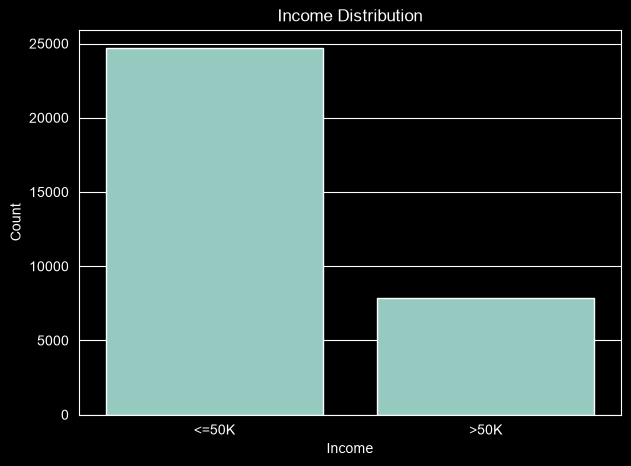

In [29]:
# visualize
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x='income')

plt.title('Income Distribution')
plt.xlabel('Income')
plt.ylabel('Count')

plt.show()

## EDA experiments

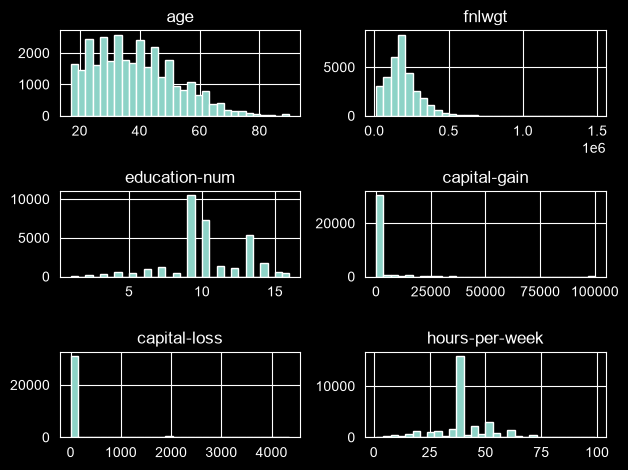

In [32]:
# analyze numerical features
numerical_features = [
    'age',
    'fnlwgt',
    'education-num',
    'capital-gain',
    'capital-loss',
    'hours-per-week'
]


df_clean[numerical_features].hist(
    bins=30,
)
plt.tight_layout()
plt.show()

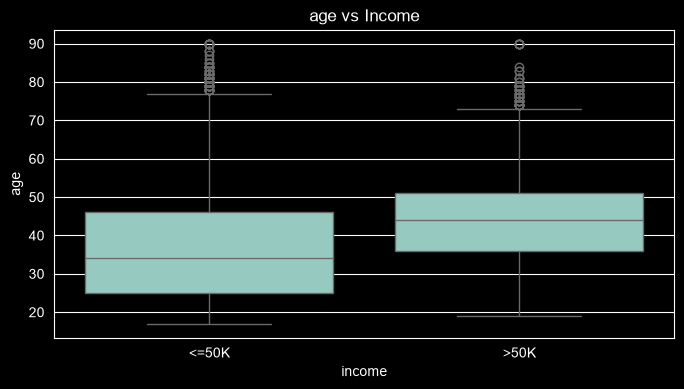

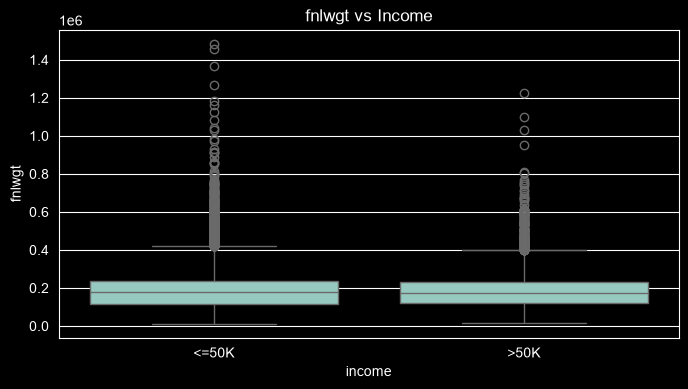

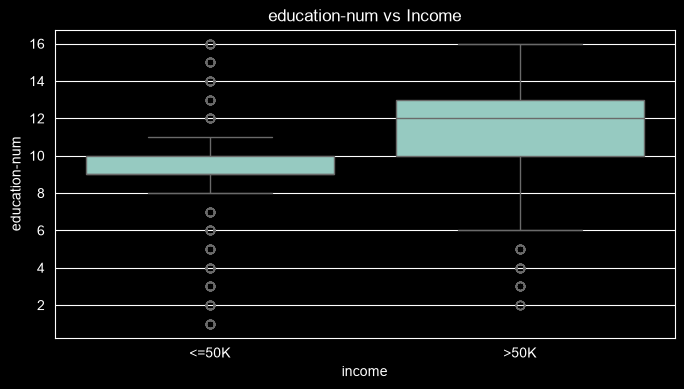

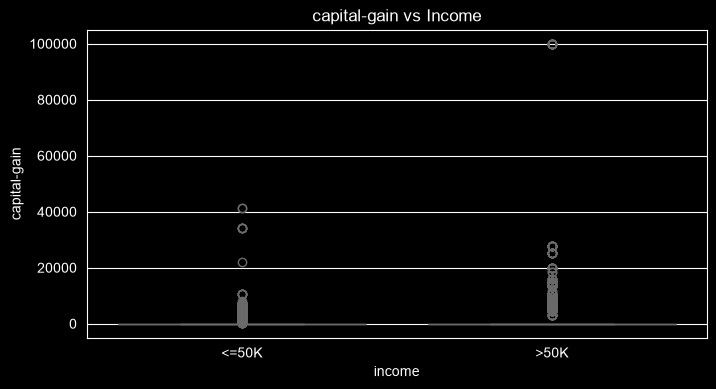

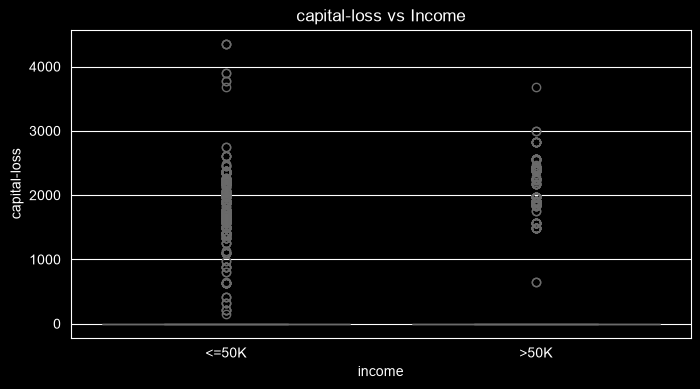

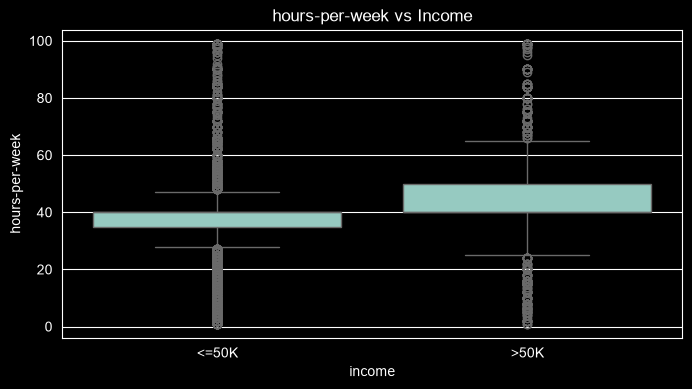

In [33]:
# correalation of target with features
for column in numerical_features:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df_clean,
        x='income',
        y=column
    )

    plt.title(f'{column} vs Income')
    plt.show()

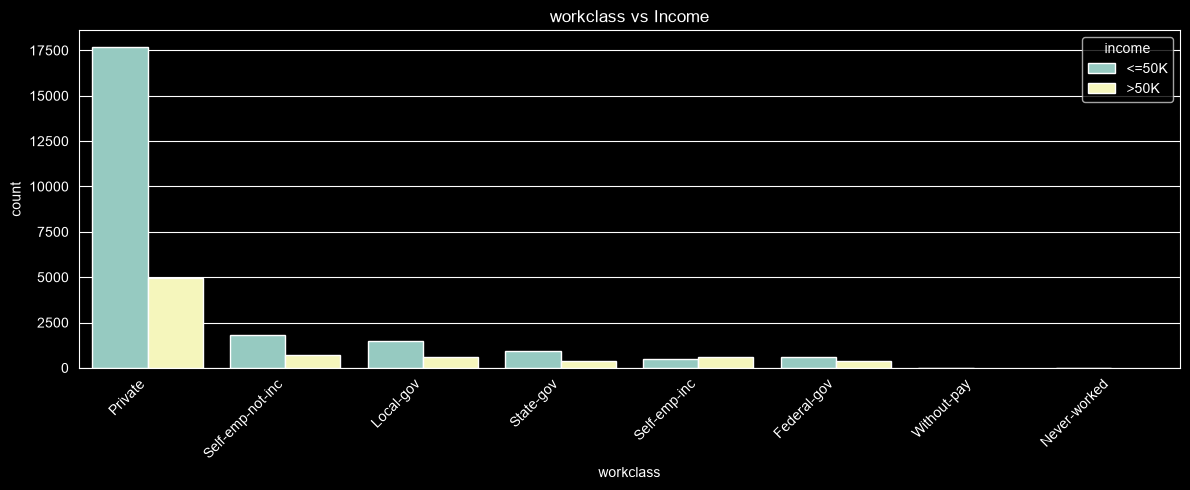

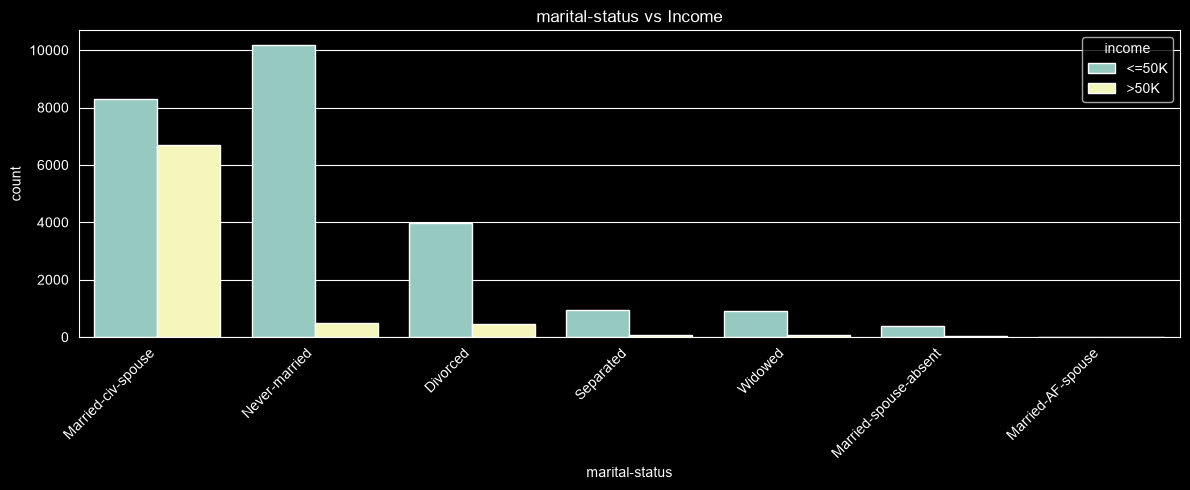

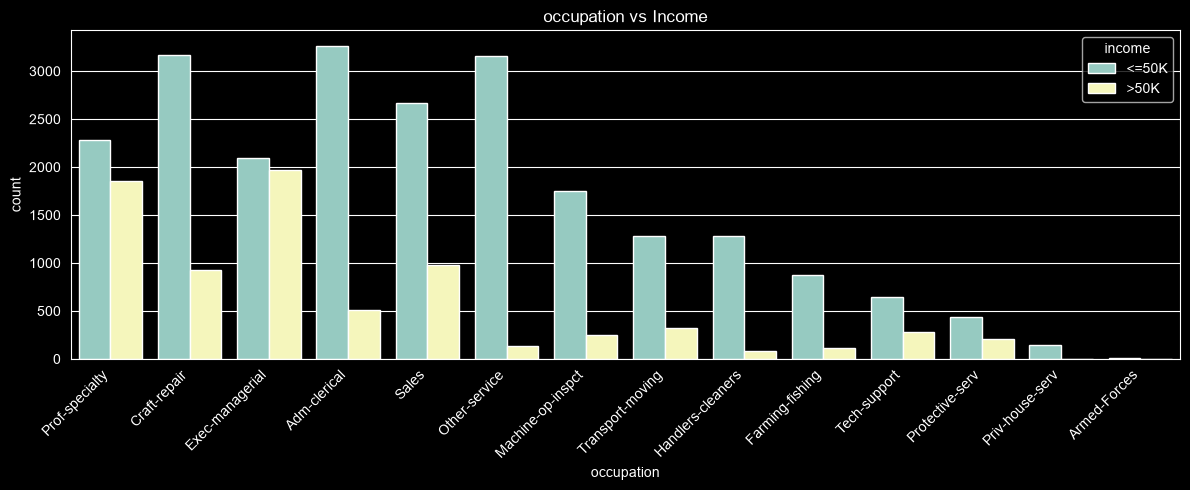

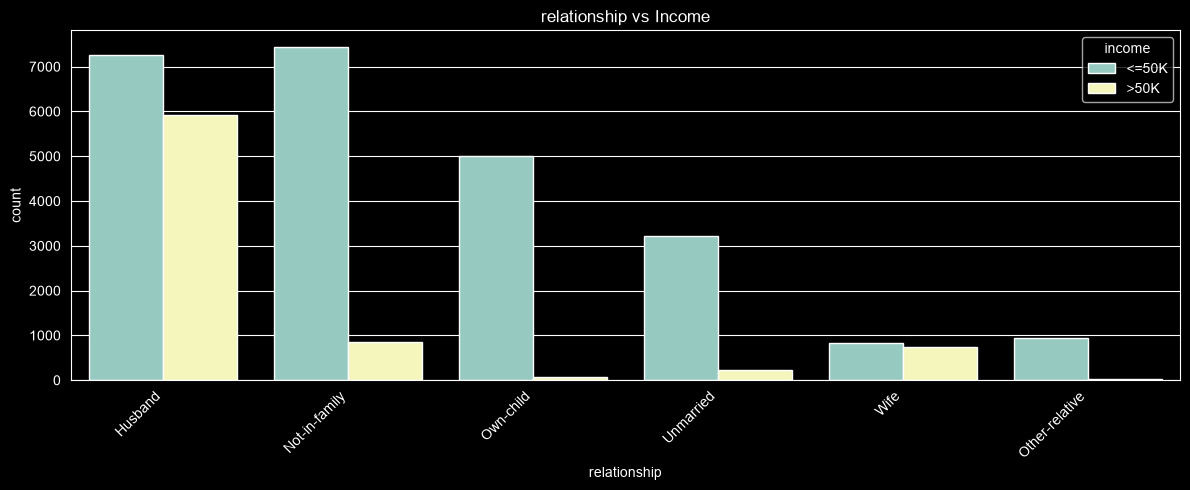

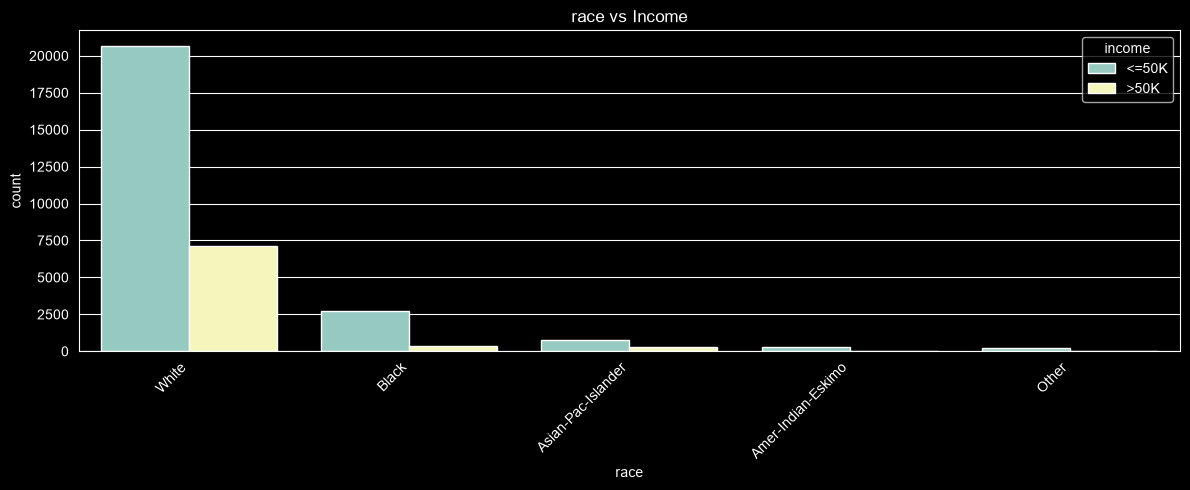

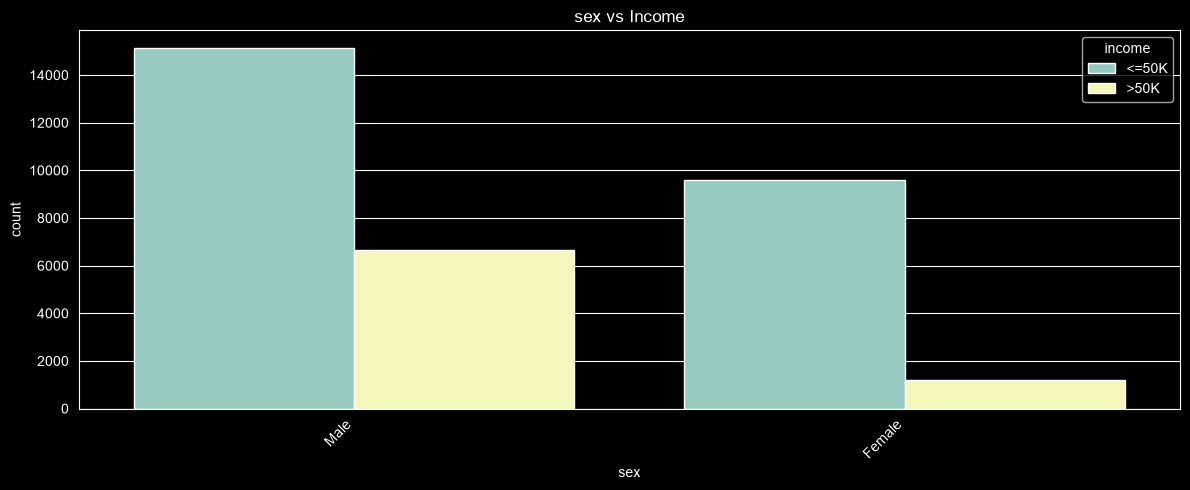

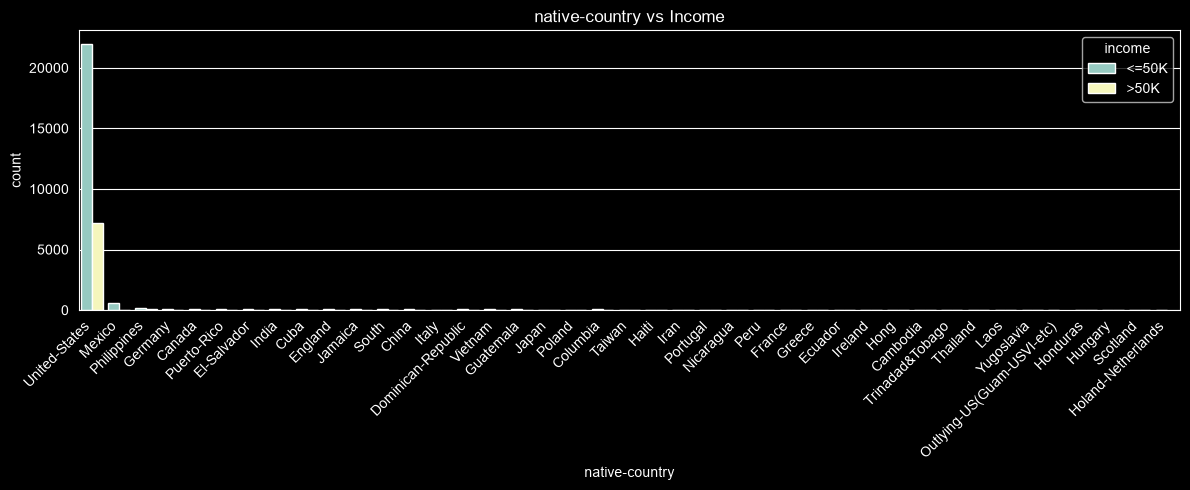

In [34]:
# analyze categorical features
categorical_features = [
    'workclass',
    'marital-status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'native-country'
]

for column in categorical_features:
    plt.figure(figsize=(12, 5))

    sns.countplot(
        data=df_clean,
        x=column,
        hue='income',
        order=df_clean[column].value_counts().index
    )

    plt.title(f'{column} vs Income')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

### some ideas to EDA

In [35]:
# missing values count and percentage
missing = pd.DataFrame({
    'Missing': df_clean.isnull().sum(),
    'Percentage': df_clean.isnull().mean() * 100
})

missing = missing[missing['Missing'] > 0]

print(missing)

                Missing  Percentage
workclass          1836    5.642807
occupation         1843    5.664321
native-country      582    1.788733


In [36]:
for column in ['workclass', 'occupation', 'native-country']:

    print(f"\n{column}:")

    print(
        pd.crosstab(
            df_clean[column].isnull(),
            df_clean['income'],
            normalize='columns'
        ) * 100
    )


workclass:
income         <=50K       >50K
workclass                      
False      93.339542  97.563465
True        6.660458   2.436535

occupation:
income          <=50K       >50K
occupation                      
False       93.311199  97.563465
True         6.688801   2.436535

native-country:
income              <=50K       >50K
native-country                      
False           98.234675  98.137518
True             1.765325   1.862482


income         <=50K       >50K
age_group                      
Under 25   98.218750   1.781250
25-35      81.304348  18.695652
35-45      65.371643  34.628357
45-55      60.137333  39.862667
55-65      68.509041  31.490959
65+        79.861711  20.138289


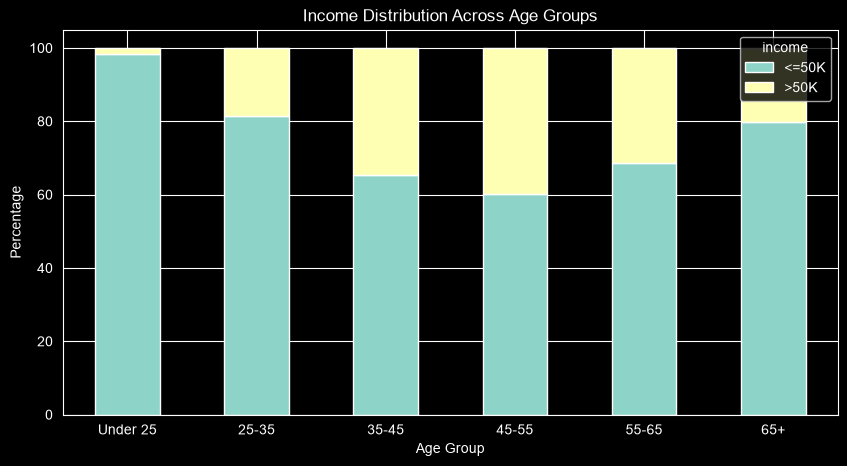

In [39]:
# age groups vs income
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['Under 25', '25-35', '35-45',
            '45-55', '55-65', '65+']
)

age_income = pd.crosstab(
    df_clean['age_group'],
    df_clean['income'],
    normalize='index'
) * 100

print(age_income)

age_income.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.title('Income Distribution Across Age Groups')
plt.ylabel('Percentage')
plt.xlabel('Age Group')
plt.xticks(rotation=0)
plt.show()

income              <=50K       >50K
education-num                       
1              100.000000   0.000000
2               96.385542   3.614458
3               95.180723   4.819277
4               93.798450   6.201550
5               94.747082   5.252918
6               93.354770   6.645230
7               94.893617   5.106383
8               92.378753   7.621247
9               84.048027  15.951973
10              80.966767  19.033233
11              73.878437  26.121563
12              75.164011  24.835989
13              58.509247  41.490753
14              44.308943  55.691057
15              26.562500  73.437500
16              25.907990  74.092010


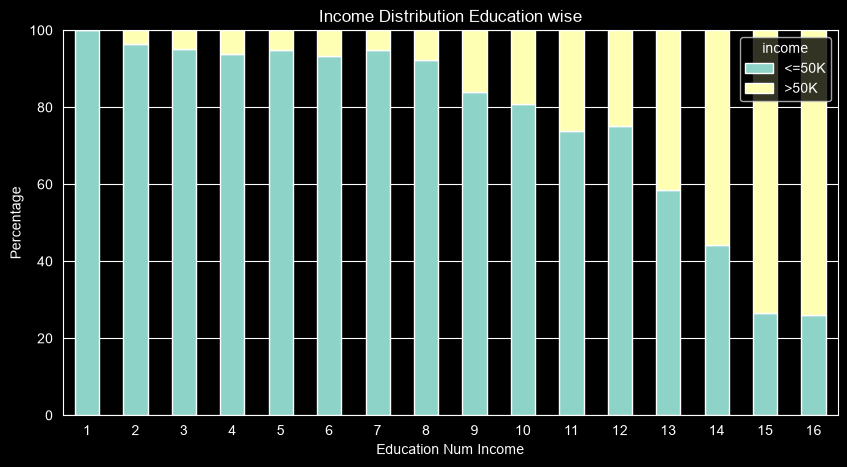

In [42]:
# education vs income
education_num_income = pd.crosstab(
    df_clean['education-num'],
    df_clean['income'],
    normalize='index'
) * 100

print(education_num_income)

education_num_income.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.title('Income Distribution Education wise')
plt.ylabel('Percentage')
plt.xlabel('Education Num Income')
plt.xticks(rotation=0)
plt.show()

income              <=50K       >50K
hours-per-week                      
1               90.000000  10.000000
2               75.000000  25.000000
3               97.435897   2.564103
4               94.444444   5.555556
5               88.333333  11.666667
...                   ...        ...
95              50.000000  50.000000
96              80.000000  20.000000
97              50.000000  50.000000
98              72.727273  27.272727
99              70.588235  29.411765

[94 rows x 2 columns]


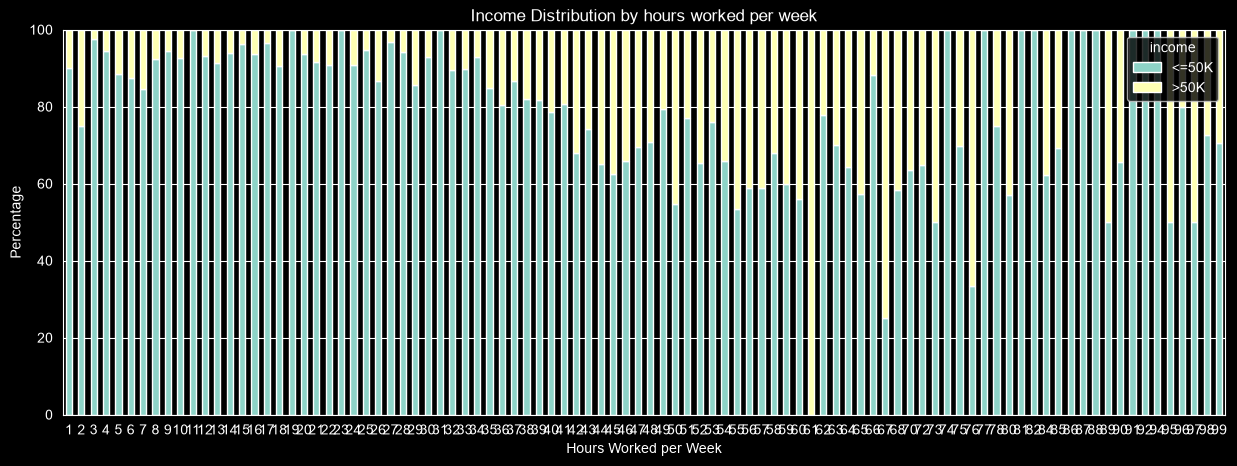

In [45]:
# hours per week vs income
hours_per_week_income = pd.crosstab(
    df_clean['hours-per-week'],
    df_clean['income'],
    normalize='index'
) * 100

print(hours_per_week_income)

hours_per_week_income.plot(
    kind='bar',
    stacked=True,
    figsize=(15, 5)
)

plt.title('Income Distribution by hours worked per week')
plt.ylabel('Percentage')
plt.xlabel('Hours Worked per Week')
plt.xticks(rotation=0)
plt.show()

In [46]:
# analyze capital gain and loss
for column in ['capital-gain', 'capital-loss']:

    zero_count = (df_clean[column] == 0).sum()
    nonzero_count = (df_clean[column] > 0).sum()

    print(f"\n{column}")
    print("Zero values:", zero_count)
    print("Non-zero values:", nonzero_count)
    print("Zero percentage:", round(
        (zero_count / len(df_clean)) * 100, 2
    ))


capital-gain
Zero values: 29825
Non-zero values: 2712
Zero percentage: 91.66

capital-loss
Zero values: 31018
Non-zero values: 1519
Zero percentage: 95.33


In [48]:
# correlation of features with target
df_clean['income_encoded'] = (
    df_clean['income'] == '>50K'
).astype(int)

correlation_with_income = (
    df_clean[numerical_features + ['income_encoded']]
    .corr()['income_encoded']
    .sort_values(ascending=False)
)

print(correlation_with_income)

income_encoded    1.000000
education-num     0.335272
age               0.234037
hours-per-week    0.229658
capital-gain      0.223336
capital-loss      0.150501
fnlwgt           -0.009502
Name: income_encoded, dtype: float64


# Feature engineering

In [78]:
# Feature engineering

# create a new modeling dataset
model_df = df_clean.copy()

# remove columns created only for EDA
model_df.drop(
    columns=[
        'age_group',
        'has_capital-gain',
        'has_capital-loss',
        'income_encoded'
    ],
    errors='ignore',
    inplace=True
)


# 1. Capital-related features

model_df['has_capital_gain'] = (
    model_df['capital-gain'] > 0
).astype(int)

model_df['has_capital_loss'] = (
    model_df['capital-loss'] > 0
).astype(int)

model_df['net_capital'] = (
    model_df['capital-gain'] -
    model_df['capital-loss']
)


# 2. Potential work experience
model_df['potential_experience'] = (
    model_df['age'] -
    model_df['education-num'] -
    6
).clip(lower=0)


# 3. Overtime indicator
model_df['is_overtime'] = (
    model_df['hours-per-week'] > 40
).astype(int)


# 4. Marital status indicator
model_df['is_married'] = (
    model_df['marital-status'].isin([
        'Married-civ-spouse',
        'Married-AF-spouse'
    ])
).astype(int)


# Handle missing categorical values
categorical_features = [
    'workclass',
    'marital-status',
    'occupation',
    'relationship',
    'race',
    'sex',
    'native-country'
]

model_df[categorical_features] = (
    model_df[categorical_features].fillna('Unknown')
)


# Check results
print("Final dataset shape:", model_df.shape)
print("\nMissing values:", model_df.isnull().sum().sum())
print("\nNew features:")
print(model_df[
    [
        'potential_experience',
        'is_overtime',
        'is_married'
    ]
].head())

model_df.head()

Final dataset shape: (32537, 20)

Missing values: 0

New features:
   potential_experience  is_overtime  is_married
0                    20            0           0
1                    31            0           1
2                    23            0           0
3                    40            0           1
4                     9            0           1


,age,workclass,fnlwgt,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,has_capital_gain,has_capital_loss,net_capital,potential_experience,is_overtime,is_married
0,39,State-gov,77516,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,1,0,2174,20,0,0
1,50,Self-emp-not-inc,83311,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0,0,0,31,0,1
2,38,Private,215646,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0,0,0,23,0,0
3,53,Private,234721,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0,0,0,40,0,1
4,28,Private,338409,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0,0,0,9,0,1


# Model training with XGBoost

In [79]:
# separate target and features
X = model_df.drop(columns=['income'])
y = (model_df['income'] == '>50K').astype(int)

print("Features shape:", X.shape)
print("Target distribution: ", y.value_counts(normalize=True) * 100)

Features shape: (32537, 19)
Target distribution:  income
0    75.907428
1    24.092572
Name: proportion, dtype: float64


In [80]:
from sklearn.model_selection import train_test_split

# train/test split
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# train/valid split
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full,test_size=0.2,random_state=42,stratify=y_train_full)



In [81]:
# encode categorical features
X_train = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_valid = pd.get_dummies(X_valid, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, drop_first=True, dtype=int)

print(X_train.shape)
print(X_valid.shape)
print(X_test.shape)

X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0) # fix error

(20823, 91)
(5206, 88)
(6508, 90)


## Baseline model

In [82]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [83]:
# evaluate model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_valid_pred = xgb_model.predict(X_valid)

y_valid_proba = xgb_model.predict_proba(X_valid)[:, 1]

print("Baseline XGBoost Performance")

print("Accuracy:", accuracy_score(y_valid, y_valid_pred))
print("Precision:", precision_score(y_valid, y_valid_pred))
print("Recall:", recall_score(y_valid, y_valid_pred))
print("F1-score:", f1_score(y_valid, y_valid_pred))
print("ROC-AUC:", roc_auc_score(y_valid, y_valid_proba))
print('Classification Report:')
print(classification_report(y_valid, y_valid_pred))

Baseline XGBoost Performance
Accuracy: 0.8709181713407607
Precision: 0.7729831144465291
Recall: 0.6570972886762361
F1-score: 0.7103448275862069
ROC-AUC: 0.9261876166308299
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.94      0.92      3952
           1       0.77      0.66      0.71      1254

    accuracy                           0.87      5206
   macro avg       0.83      0.80      0.81      5206
weighted avg       0.87      0.87      0.87      5206



## Random Grid search, and GridSearchCV

In [84]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform
from xgboost import XGBClassifier

# Focus on the 5 most critical hyperparameters
param_distributions = {
    'n_estimators': randint(100, 500),
    'max_depth': randint(3, 8),
    'learning_rate': uniform(0.01, 0.2),
    'subsample': uniform(0.7, 0.3),         # Values between 0.7 and 1.0
    'colsample_bytree': uniform(0.7, 0.3)   # Values between 0.7 and 1.0
}

# Quick setup with Stratified K-Fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=XGBClassifier(random_state=42),
    param_distributions=param_distributions,
    n_iter=35,          # Number of parameter settings sampled
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1
)
search.fit(X_train, y_train)

print(search.best_params_)
# {'colsample_bytree': np.float64(0.9077308098670811), 'learning_rate': np.float64(0.0638824667597043), 'max_depth': 5, 'n_estimators': 473, 'subsample': np.float64(0.765629265871921)}
print(search.best_score_) # 0.7095224027200776


{'colsample_bytree': np.float64(0.9720485324637261), 'learning_rate': np.float64(0.06442644987692707), 'max_depth': 5, 'n_estimators': 220, 'subsample': np.float64(0.9454044297767479)}
0.7086265569786302


In [75]:
best_random_model = search.best_estimator_

y_valid_pred_random = best_random_model.predict(X_valid)

y_valid_proba_random = best_random_model.predict_proba(X_valid)[:, 1]

print("Optimized XGBoost Performance")

print("Accuracy:",
      accuracy_score(y_valid, y_valid_pred_random))

print("Precision:",
      precision_score(y_valid, y_valid_pred_random))

print("Recall:",
      recall_score(y_valid, y_valid_pred_random))

print("F1-score:",
      f1_score(y_valid, y_valid_pred_random))

print("ROC-AUC:",
      roc_auc_score(y_valid, y_valid_proba_random))

print("\nClassification Report:")

print(classification_report(y_valid, y_valid_pred_random))

Optimized XGBoost Performance
Accuracy: 0.8730311179408375
Precision: 0.7659192825112108
Recall: 0.6810207336523126
F1-score: 0.7209793161671592
ROC-AUC: 0.9259202535691456

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.93      0.92      3952
           1       0.77      0.68      0.72      1254

    accuracy                           0.87      5206
   macro avg       0.83      0.81      0.82      5206
weighted avg       0.87      0.87      0.87      5206



In [76]:
# Normal GridSearchCV
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [4, 5, 6],
    'n_estimators': [400, 475, 550],
    'learning_rate': [0.04, 0.06, 0.08],
    'subsample': [0.70, 0.77, 0.85],
    'colsample_bytree': [0.85, 0.90, 0.95]
}

grid_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=1
)

grid_search = GridSearchCV(
    estimator=grid_model,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    verbose=1,
    n_jobs=-1,
    return_train_score=True
)
grid_search.fit(X_train, y_train)

print(grid_search.best_params_)
print(grid_search.best_score_)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits
{'colsample_bytree': 0.95, 'learning_rate': 0.08, 'max_depth': 4, 'n_estimators': 400, 'subsample': 0.85}
0.7129073574869831


In [77]:
best_grid_model = grid_search.best_estimator_

y_grid_pred = best_grid_model.predict(X_valid)

y_grid_proba = best_grid_model.predict_proba(X_valid)[:, 1]

print("Accuracy:", accuracy_score(y_valid, y_grid_pred))
print("Precision:", precision_score(y_valid, y_grid_pred))
print("Recall:", recall_score(y_valid, y_grid_pred))
print("F1-score:", f1_score(y_valid, y_grid_pred))
print("ROC-AUC:", roc_auc_score(y_valid, y_grid_proba))

print("\n", classification_report(y_valid, y_grid_pred))

Accuracy: 0.870149827122551
Precision: 0.7617753623188406
Recall: 0.6706539074960127
F1-score: 0.7133163698049194
ROC-AUC: 0.9272448609792792

               precision    recall  f1-score   support

           0       0.90      0.93      0.92      3952
           1       0.76      0.67      0.71      1254

    accuracy                           0.87      5206
   macro avg       0.83      0.80      0.81      5206
weighted avg       0.87      0.87      0.87      5206

